# 25 · Limits of the final model (E55-E58)

- **E55** leakage audit: folds grouped by brand ∪ author ∪ identical text, and random folds;
- **E56** noise ceiling from posts with almost the same inputs;
- **E57** quantile models (10/50/90%) and tail weighting;
- **E58** abstention curve.

Final model: CatBoost MAE on followers + reactions + flags; MAE of log10(views).

In [1]:
import sys, json, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw" / "reach_samples_students.csv").exists())
sys.path.insert(0, str(ROOT / "src"))
FIG = ROOT / "figures"; plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 220, "display.max_columns", 30)
import eda_utils as eu, extra_models as em, history as H, limits as L

In [2]:
f, meta = em.load(ROOT); raw = eu.load(ROOT).loc[f.index]

## E55 · Leakage audit

In [3]:
PL, info = L.leakage(f, meta, raw); info.round(3)

,platform,posts,brands,components,largest component share
0,tiktok,2491,266,174,0.279
1,youtube,2441,273,156,0.404
2,twitter,1803,252,159,0.344


In [4]:
SL = H.summarise(PL); SL.round(3)

,platform,model,posts,MAE,CI low,CI high,bias
0,tiktok,brand folds (usual),2491,0.273,0.263,0.285,-0.020
1,tiktok,brand ∪ author ∪ text folds,2491,0.272,0.261,0.283,-0.022
2,tiktok,random folds (brands seen),2491,0.270,0.260,0.282,-0.019
3,youtube,brand folds (usual),2441,0.456,0.434,0.480,-0.039
4,youtube,brand ∪ author ∪ text folds,2441,0.457,0.435,0.479,-0.032
5,youtube,random folds (brands seen),2441,0.447,0.426,0.472,-0.040
6,twitter,brand folds (usual),1803,0.466,0.446,0.489,-0.039
7,twitter,brand ∪ author ∪ text folds,1803,0.477,0.457,0.499,-0.018
8,twitter,random folds (brands seen),1803,0.469,0.448,0.491,-0.038


In [5]:
GL = pd.DataFrame([{"platform": p, "model": k, **dict(zip(["gain", "CI low", "CI high"], H.gain_ci(PL, p, "brand folds (usual)", k)))} for p in L.PLATS for k in ["brand ∪ author ∪ text folds", "random folds (brands seen)"]]); GL.round(3)

,platform,model,gain,CI low,CI high
0,tiktok,brand ∪ author ∪ text folds,0.002,0.000,0.003
1,tiktok,random folds (brands seen),0.003,0.001,0.005
2,youtube,brand ∪ author ∪ text folds,-0.001,-0.004,0.003
3,youtube,random folds (brands seen),0.009,0.004,0.012
4,twitter,brand ∪ author ∪ text folds,-0.011,-0.020,-0.003
5,twitter,random folds (brands seen),-0.002,-0.006,0.002


## E56 · Noise ceiling

In [6]:
N = L.noise_ceiling(f, meta); N.round(3)

,platform,pairs,posts in pairs,mean |Δ log views|,lower bound on MAE (½ mean |Δ|),final model MAE on these posts,"final model MAE, all posts"
0,tiktok,183,304,0.446,0.223,0.325,0.274
1,youtube,639,866,0.775,0.388,0.578,0.454
2,twitter,999,1301,0.666,0.333,0.471,0.467


## E57 · Quantile models and tail weighting

In [7]:
Qd = L.quantiles(f, meta); IT = L.interval_table(Qd); IT.round(3)

,platform,fifth of true views,posts,coverage 10-90%,median width (×),MAE q50,MAE final,MAE tail weighted,bias final,bias tail weighted
0,tiktok,all,2491,0.731,5.415,0.274,0.273,0.275,-0.020,-0.018
1,tiktok,lowest,499,0.739,7.483,0.321,0.321,0.320,0.275,0.277
2,tiktok,2,498,0.817,4.821,0.179,0.178,0.183,0.039,0.035
3,tiktok,3,498,0.819,4.875,0.211,0.210,0.212,-0.058,-0.058
4,tiktok,4,498,0.737,6.146,0.296,0.294,0.299,-0.133,-0.126
5,tiktok,highest,498,0.544,4.865,0.362,0.363,0.361,-0.223,-0.220
6,youtube,all,2441,0.727,14.106,0.449,0.456,0.458,-0.039,-0.043
7,youtube,lowest,489,0.703,33.231,0.575,0.586,0.567,0.491,0.481
8,youtube,2,488,0.840,18.538,0.379,0.377,0.394,0.057,0.034
9,youtube,3,488,0.820,11.360,0.336,0.338,0.351,-0.048,-0.047


In [8]:
Qp = pd.concat([Qd.assign(model=k, pred=Qd[c]) for k, c in [("final model", "final model"), ("tail weighted", "tail weighted"), ("median (q50)", "q50")]])
GQ = pd.DataFrame([{"platform": p, "model": k, **dict(zip(["gain", "CI low", "CI high"], H.gain_ci(Qp, p, "final model", k)))} for p in L.PLATS for k in ["tail weighted", "median (q50)"]]); GQ.round(3)

,platform,model,gain,CI low,CI high
0,tiktok,tail weighted,-0.002,-0.003,-0.000
1,tiktok,median (q50),-0.001,-0.002,0.001
2,youtube,tail weighted,-0.002,-0.005,0.001
3,youtube,median (q50),0.007,0.003,0.010
4,twitter,tail weighted,-0.001,-0.003,0.002
5,twitter,median (q50),-0.001,-0.004,0.001


## E58 · Abstention curve

In [9]:
A = L.abstention(Qd); A.pivot_table(index=["platform", "kept"], columns="ranking", values="MAE").round(3)

ranking        oracle (true error)  quantile width  random  reaction-tier width
platform kept                                                                  
tiktok   0.1                 0.016           0.272   0.256                0.243
         0.2                 0.032           0.249   0.264                0.241
         0.3                 0.052           0.245   0.276                0.243
         0.4                 0.072           0.244   0.275                0.239
         0.5                 0.093           0.246   0.274                0.248
         0.6                 0.115           0.248   0.275                0.251
         0.7                 0.140           0.254   0.274                0.259
         0.8                 0.168           0.256   0.273                0.262
         0.9                 0.205           0.257   0.276                0.263
         1.0                 0.273           0.273   0.273                0.273
twitter  0.1                 0.032           0.419   0.495                0.378
         0.2                 0.067           0.421   0.473                0.416
         0.3                 0.102           0.430   0.459                0.430
         0.4                 0.140           0.429   0.469                0.440
         0.5                 0.178           0.439   0.469                0.448
         0.6                 0.220           0.438   0.472                0.458
         0.7                 0.265           0.450   0.469                0.458
         0.8                 0.315           0.457   0.473                0.462
         0.9                 0.375           0.460   0.470                0.467
         1.0                 0.466           0.466   0.466                0.466
youtube  0.1                 0.034           0.294   0.449                0.287
         0.2                 0.066           0.306   0.461                0.303
         0.3                 0.098           0.315   0.458                0.316
         0.4                 0.132           0.323   0.456                0.333
         0.5                 0.168           0.334   0.461                0.348
         0.6                 0.204           0.353   0.458                0.360
         0.7                 0.245           0.373   0.459                0.376
         0.8                 0.291           0.399   0.458                0.408
         0.9                 0.349           0.431   0.453                0.433
         1.0                 0.456           0.456   0.456                0.456

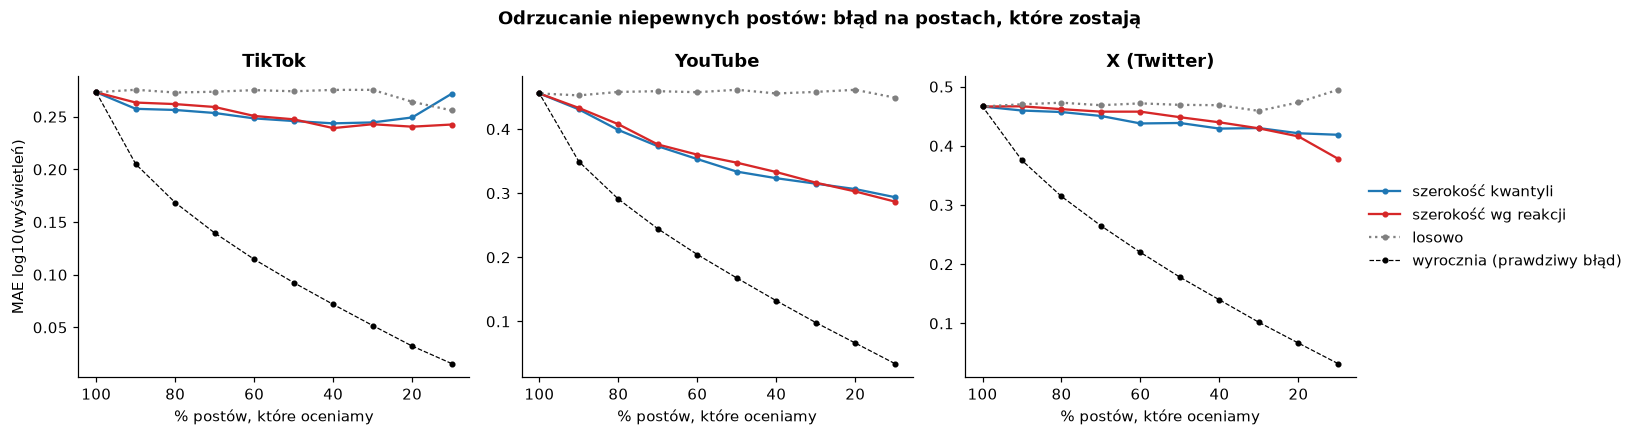

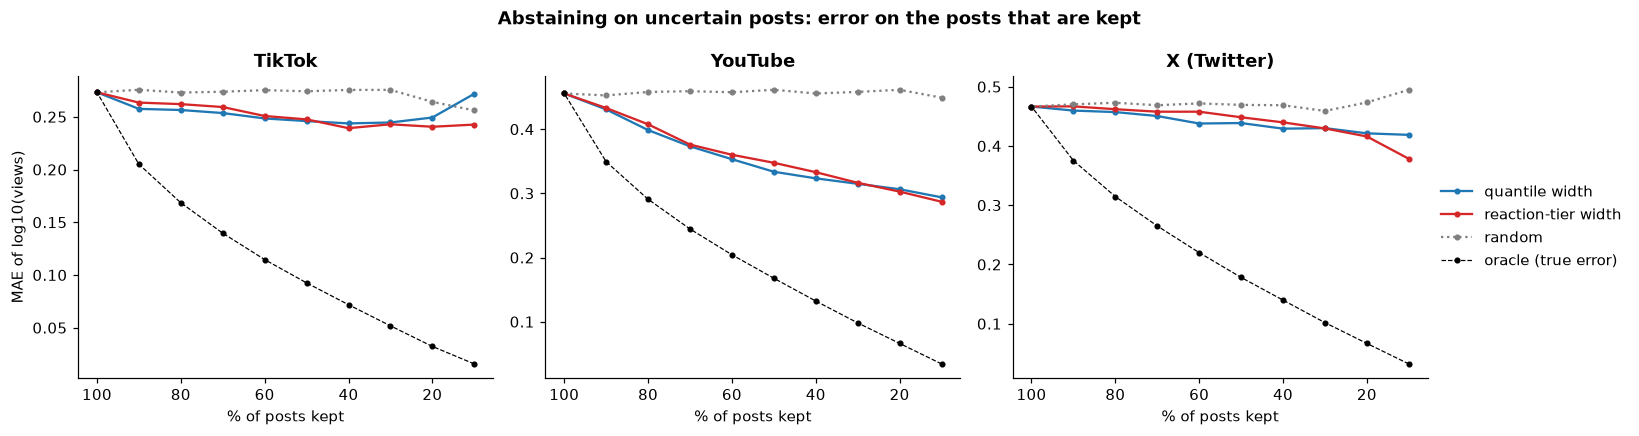

In [10]:
for l in ("pl", "en"): L.plot_abstention(A, FIG / f"abstention_{l}.png", l)

## Takeaways
See `docs/en/experiments.md` (E55-E58) and the vault cards. Numbers: `data/processed/limits_numbers.json`.

In [11]:
json.dump({"leakage_info": info.to_dict("records"), "leakage": SL.to_dict("records"), "leakage_gains": GL.to_dict("records"), "noise_ceiling": N.to_dict("records"), "intervals": IT.to_dict("records"), "quantile_gains": GQ.to_dict("records"), "abstention": A.to_dict("records")},
          open(ROOT / "data" / "processed" / "limits_numbers.json", "w"), indent=1, default=float)